# ДЗ 1. Прогнозирование продаж: анализ и предобработка временного ряда

Курс «Прогнозирование временных рядов и обработка сигналов».

Я разбираю продажи товара 85099B (JUMBO BAG RED RETROSPOT). На лекции был другой товар, 85123A.

Все функции лежат в `src/ts_tools.py`, а в ноутбуке только их вызовы, графики и мои выводы. Корень репозитория ноутбук находит сам, выполнять его нужно сверху вниз.

In [30]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ищем корень репозитория (там, где лежит src/ts_tools.py), откуда бы ни запустили ноутбук
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ts_tools.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Не нашел src/ts_tools.py. Откройте ноутбук из папки репозитория "
                            "и убедитесь, что папка src лежит рядом с ним.")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import ts_tools as T

from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 100
Path("figures").mkdir(exist_ok=True)


def show(name):
    """Сохраняем текущий график в figures/ (для README) и показываем."""
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Шаг 1. Данные и формирование временного ряда

Если файла с данными нет, он скачается с UCI.

In [31]:
DATA_FILE = Path("data/Online Retail.xlsx")

if not DATA_FILE.exists():
    import io, urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    with urllib.request.urlopen(url) as resp:
        zf = zipfile.ZipFile(io.BytesIO(resp.read()))
    name = [n for n in zf.namelist() if n.lower().endswith(".xlsx")][0]
    DATA_FILE.parent.mkdir(exist_ok=True)
    DATA_FILE.write_bytes(zf.read(name))

df = T.load_retail(DATA_FILE)
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


In [32]:
df.info()
print()
print("Пропуски по столбцам:")
print(df.isna().sum())
print()
print("Доля счетов-возвратов (InvoiceNo на C):", round(df["InvoiceNo"].str.startswith("C").mean(), 4))
print("Строк с Quantity <= 0:", int((df["Quantity"] <= 0).sum()))
print("Период данных:", df["InvoiceDate"].min(), "-", df["InvoiceDate"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Пропуски по столбцам:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Доля счетов-возвратов (InvoiceNo на C): 0.0171
Строк с Quantity <= 0: 10624
Период данных: 2010

В датасете восемь полей: `InvoiceNo` (номер счёта, у возвратов он начинается с буквы C), `StockCode` (код товара), `Description` (название), `Quantity` (сколько штук в строке счёта, у возвратов отрицательное), `InvoiceDate` (дата и время), `UnitPrice` (цена за штуку), `CustomerID` и `Country`. Пропуски есть только в `Description` и `CustomerID`. Возвраты это примерно 1,7% строк, а строк с неположительным количеством 10624.

Для ряда мне нужны `StockCode` (чтобы отобрать товар), `InvoiceDate` (ось времени) и `Quantity` (показатель продаж). `InvoiceNo` нужен только чтобы убрать возвраты - отмены продажами не считаются.

Посмотрю на самые частые товары.

In [33]:
top_codes = df["StockCode"].value_counts().head(10).index
top = (df[df["StockCode"].isin(top_codes)]
       .groupby("StockCode")
       .agg(строк=("InvoiceNo", "size"),
            штук=("Quantity", "sum"),
            описание=("Description", lambda x: x.mode().iat[0]))
       .sort_values("строк", ascending=False))
top

,строк,штук,описание
StockCode,,,
85123A,2313,38830,WHITE HANGING HEART T-LIGHT HOLDER
22423,2203,12980,REGENCY CAKESTAND 3 TIER
85099B,2159,47363,JUMBO BAG RED RETROSPOT
47566,1727,18022,PARTY BUNTING
20725,1639,18979,LUNCH BAG RED RETROSPOT
84879,1502,36221,ASSORTED COLOUR BIRD ORNAMENT
22720,1477,7286,SET OF 3 CAKE TINS PANTRY DESIGN
22197,1476,56450,POPCORN HOLDER
21212,1385,36039,PACK OF 72 RETROSPOT CAKE CASES


In [34]:
STOCK = "85099B"   # на лекции был 85123A

print(df.loc[df["StockCode"] == STOCK, "Description"].value_counts(dropna=False))

prod = T.select_product(df, STOCK)
print("\nТранзакций с продажами товара:", len(prod))
print("Первая и последняя продажа:", prod["InvoiceDate"].min(), "/", prod["InvoiceDate"].max())

Description
JUMBO BAG RED RETROSPOT    2159
Name: count, dtype: int64

Транзакций с продажами товара: 2115
Первая и последняя продажа: 2010-12-01 09:57:00 / 2011-12-09 10:26:00


Товар выбрала так: в таблице выше 85099B третий по числу строк (2159) и при этом не тот, что разбирали на лекции (85123A, первая строка). Название у него одно, так что код не двоится. По числу строк видно, что товар продаётся часто, значит, данных для анализа должно хватить.

Показатель продаж: количество проданных штук (`Quantity`). Выручку не беру, чтобы цена не примешивалась к спросу.

Агрегирую по дням, неделям (неделя заканчивается в воскресенье) и месяцам. Сначала получаются сырые ряды, в которых период без единой транзакции остаётся NaN, а не нулём: что это на самом деле, разберусь в шаге 2. Неполные периоды по краям отрезаю.

In [35]:
data_start, data_end = df["InvoiceDate"].min(), df["InvoiceDate"].max()
open_days = T.shop_open_days(df)

FREQS = {"D": ("день", "D"), "W": ("неделя", "W-SUN"), "MS": ("месяц", "M")}
raw = {}
for f, (label, pf) in FREQS.items():
    s = T.trim_to_sales_span(T.aggregate(prod, f))
    raw[f] = T.drop_partial_edges(s, data_start, data_end, pf)

summary = pd.DataFrame({
    FREQS[f][0]: {"наблюдений": len(s), "начало": s.index[0].date(),
                  "конец": s.index[-1].date(), "пустых периодов (NaN)": int(s.isna().sum())}
    for f, s in raw.items()
}).T
summary

,наблюдений,начало,конец,пустых периодов (NaN)
день,373,2010-12-01,2011-12-08,73
неделя,52,2010-12-12,2011-12-04,1
месяц,12,2010-12-01,2011-11-01,0


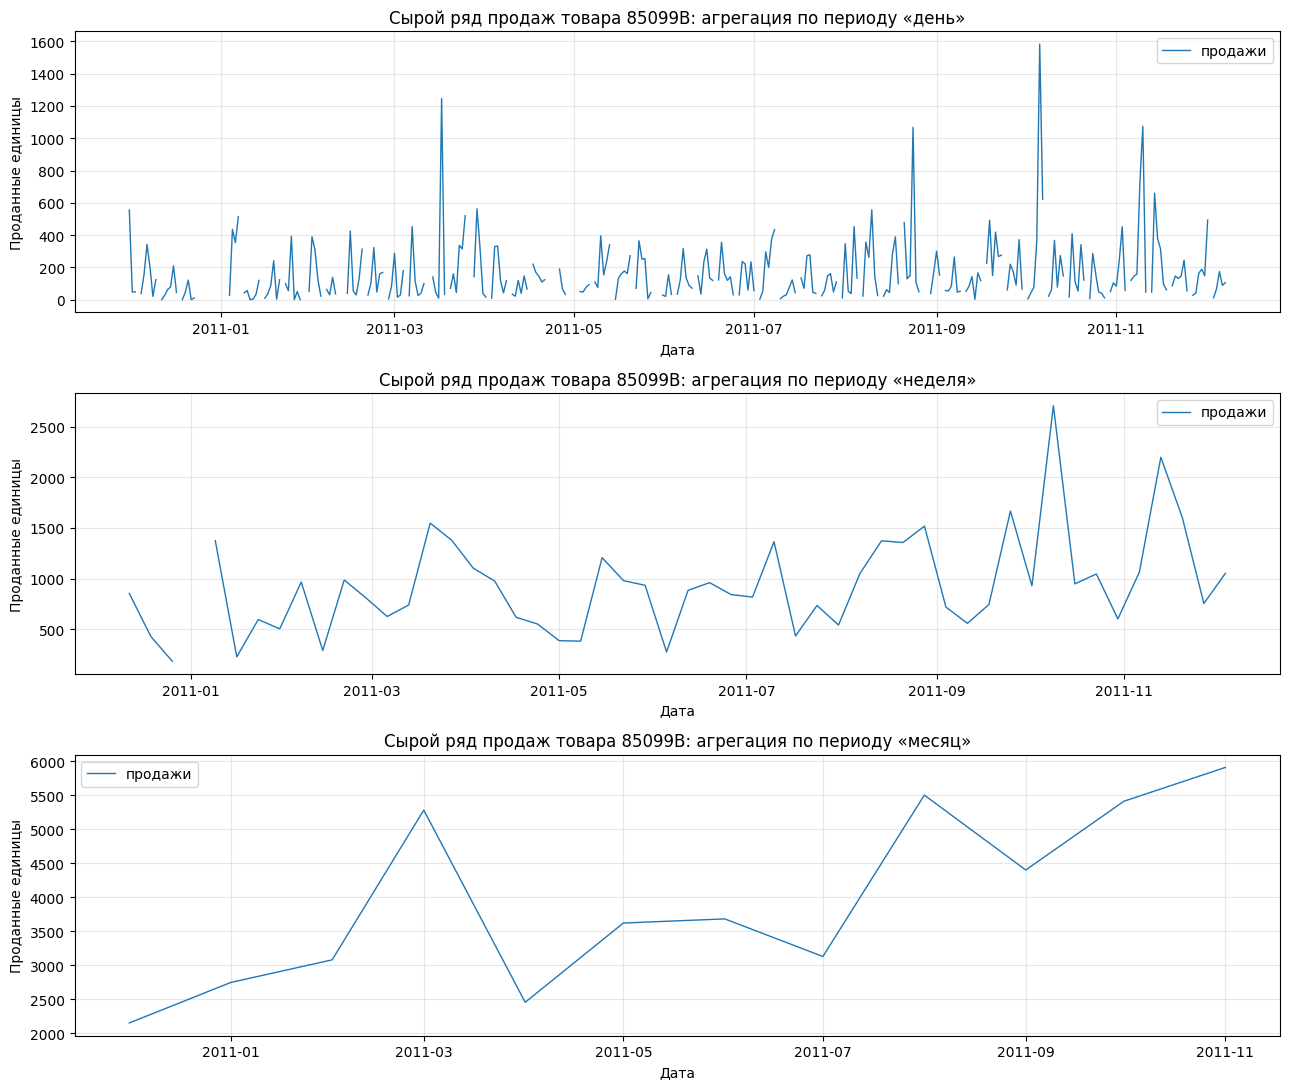

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, (f, s) in zip(axes, raw.items()):
    T.plot_series(s, f"Сырой ряд продаж товара {STOCK}: агрегация по периоду «{FREQS[f][0]}»",
                  "Проданные единицы", ax=ax)
fig.tight_layout()
show("01_raw_all_freq")

В итоге получилось 373 дня (с 1 декабря 2010 по 8 декабря 2011), 52 недели и 12 месяцев. На графиках видно, что продажи растут к осени: самое низкое месячное значение 2 152 штуки (в начале ряда), самое высокое 5 909 (в конце). В дневном ряду много коротких «иголок», в недельном самый высокий пик, 2 709 штук, приходится на начало октября.

## Шаг 2. Качество данных

### Пропуски

Сначала нужно понять, что значит пустой день: товар не покупали или магазин не работал. Первое это настоящий ноль продаж, второе вообще не наблюдение, и ставить туда ноль нельзя. Различить их можно по всему датасету: если в этот день нет ни одной транзакции ни по одному товару, магазин, скорее всего, был закрыт.

In [37]:
rep = T.missing_report(raw["D"])
print(f"Дневной ряд: {rep['n_missing']} пустых дней из {rep['n_total']} ({rep['share_missing']:.1%})")
print("Число отдельных пустых отрезков:", len(rep["runs"]))
print("Самые длинные пустые отрезки:")
print(rep["runs"].sort_values("length", ascending=False).head(5).to_string(index=False))

print("\nНа какие дни недели приходятся пустые дни:")
print(T.weekday_gaps(raw["D"]).to_string())

zero_days, closed_days = T.split_empty_days(raw["D"], open_days)
print(f"\nМагазин работал, товар не купили (настоящий ноль): {len(zero_days)} дней")
print(f"Магазин не работал вообще (не наблюдение):         {len(closed_days)} дней")
wd_ru = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
closed_by_wd = closed_days.dayofweek.value_counts().sort_values(ascending=False)
print("Закрытые дни по дням недели:", ", ".join(f"{wd_ru[i]}: {n}" for i, n in closed_by_wd.items()))

Дневной ряд: 73 пустых дней из 373 (19.6%)
Число отдельных пустых отрезков: 56
Самые длинные пустые отрезки:
     start        end  length
2010-12-24 2011-01-03      11
2011-04-22 2011-04-25       4
2011-03-12 2011-03-13       2
2011-01-29 2011-01-30       2
2011-04-29 2011-04-30       2

На какие дни недели приходятся пустые дни:
Пн     6
Вт     1
Ср     1
Чт     2
Пт     4
Сб    53
Вс     6

Магазин работал, товар не купили (настоящий ноль): 4 дней
Магазин не работал вообще (не наблюдение):         69 дней
Закрытые дни по дням недели: Сб: 53, Пн: 6, Пт: 4, Вс: 3, Вт: 1, Ср: 1, Чт: 1


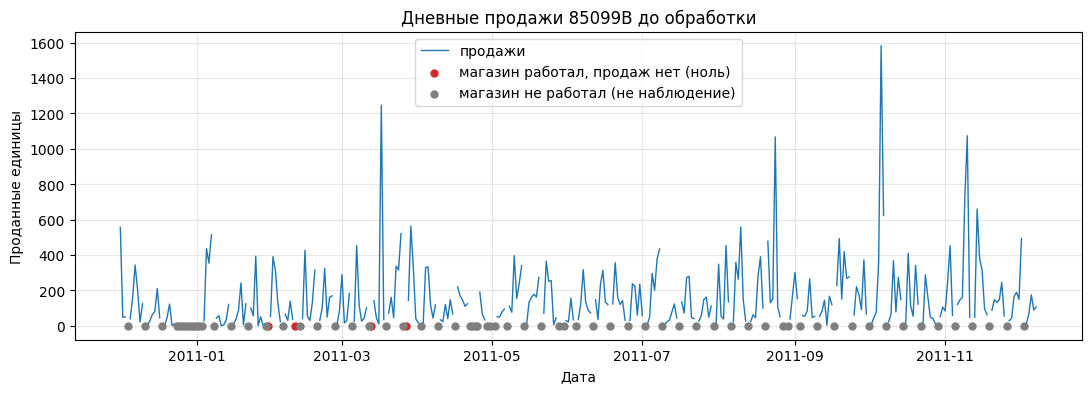

In [38]:
ax = T.plot_series(raw["D"], f"Дневные продажи {STOCK} до обработки", "Проданные единицы",
                   marks=[(pd.Series(0, index=zero_days), "магазин работал, продаж нет (ноль)", "tab:red"),
                          (pd.Series(0, index=closed_days), "магазин не работал (не наблюдение)", "tab:gray")])
show("02_daily_gaps")

Пустых дней 73 из 373 (19,6%), но почти все они объясняются закрытым магазином: 69 из 73 это дни, когда во всём датасете нет ни одной транзакции. Из них 53 субботы, то есть по субботам магазин не торгует вообще, а остальные закрытые дни выглядят как праздничные перерывы. Самые длинные из них: с 24 декабря по 3 января (11 дней) и с 22 по 25 апреля (4 дня), похоже на рождественские дни и пасху. Это не нулевой спрос, а отсутствие наблюдения, и нули туда ставить нельзя.

Настоящих нулей, когда магазин работал, а товар не купили, всего 4.

Решение по пропускам: нули ставлю только в дни, когда магазин работал, а дни без торговли убираю из дневного ряда, так что он идёт по торговому календарю. Если бы я вписала нули в закрытые дни, получились бы искусственные провалы каждую неделю.

В недельном и месячном рядах пустой период при работающем магазине тоже считается нулём, а период, где магазин не работал совсем, интерполируется. В данных такая неделя одна, она целиком попадает в перерыв с 24 декабря по 3 января.

In [39]:
daily = T.to_trading_calendar(raw["D"], open_days)

weekly = T.fill_zero_if_open(raw["W"], open_days, "W-SUN")
print("Недель, где магазин не работал совсем (остались NaN):", int(weekly.isna().sum()))
if weekly.isna().any():
    weekly = T.fill_missing(weekly, "interpolate")

monthly = T.fill_zero_if_open(raw["MS"], open_days, "M")
print("Месяцев, где магазин не работал совсем (остались NaN):", int(monthly.isna().sum()))
if monthly.isna().any():
    monthly = T.fill_missing(monthly, "interpolate")

PERIOD_D = daily.index.dayofweek.nunique()   # длина торговой недели в днях
print(f"\nДневной ряд на торговом календаре: {len(daily)} наблюдений, "
      f"из них нулевых {(daily == 0).sum()}, торговая неделя = {PERIOD_D} дн.")

Недель, где магазин не работал совсем (остались NaN): 1
Месяцев, где магазин не работал совсем (остались NaN): 0

Дневной ряд на торговом календаре: 304 наблюдений, из них нулевых 4, торговая неделя = 6 дн.


Дальше основной ряд дневной, на торговом календаре: в нём 304 наблюдения, и на нём можно искать короткий недельный цикл. Недельный (52 точки) и месячный (12 точек) нужны для сравнения, для оценки сезонности в них слишком мало данных. Все три очищенных ряда сохраняю в `data/`, чтобы они лежали в репозитории готовыми файлами.

In [40]:
files = T.save_series({"D": daily, "W": weekly, "MS": monthly}, STOCK, "data")
for key, path in files.items():
    print(key, "->", path)

pd.read_csv(files["D"], index_col="date", parse_dates=True).head()

D -> data/sales_85099B_daily.csv
W -> data/sales_85099B_weekly.csv
MS -> data/sales_85099B_monthly.csv


,quantity
date,
2010-12-01,556.000
2010-12-02,48.000
2010-12-03,49.000
2010-12-05,39.000
2010-12-06,157.000


### Выбросы

Продажи сильно скошены и с тяжёлым хвостом, поэтому одному методу я не доверяю и сравню три:

* IQR (правило Тьюки): простое, но не учитывает ни тренд, ни сезонность;
* MAD (модифицированный z-score на медиане): устойчивее к самим выбросам;
* остаток STL: сначала вычитаю тренд и недельный цикл, потом ищу аномалии в остатке.

In [41]:
m_iqr, (lo, hi) = T.iqr_outliers(daily)
m_mad, z_mad = T.mad_outliers(daily)
m_stl, resid = T.stl_residual_outliers(daily, PERIOD_D)

flags = pd.DataFrame({"IQR": m_iqr, "MAD": m_mad, "STL-остаток": m_stl})
flags["голосов"] = flags.sum(axis=1)

print(f"Граница IQR: [{lo:.0f}; {hi:.0f}]")
print("Сколько точек отметил каждый метод:")
print(flags[["IQR", "MAD", "STL-остаток"]].sum().to_string())
print("\nТочки, отмеченные минимум двумя методами:")
cand = flags[flags["голосов"] >= 2].assign(продано=daily).sort_values("продано", ascending=False)
print(cand[["продано", "голосов"]].to_string())

Граница IQR: [-222; 486]
Сколько точек отметил каждый метод:
IQR            14
MAD            15
STL-остаток    60

Точки, отмеченные минимум двумя методами:
             продано  голосов
2011-10-06 1,583.000        3
2011-03-17 1,246.000        3
2011-11-10 1,074.000        3
2011-08-24 1,068.000        3
2011-11-09   725.000        3
2011-11-14   660.000        3
2011-10-07   623.000        3
2011-03-29   563.000        3
2011-08-10   557.000        3
2010-12-01   556.000        3
2011-03-25   521.000        3
2011-01-07   514.000        3
2011-09-19   493.000        3
2011-12-02   493.000        3
2011-08-21   478.000        2


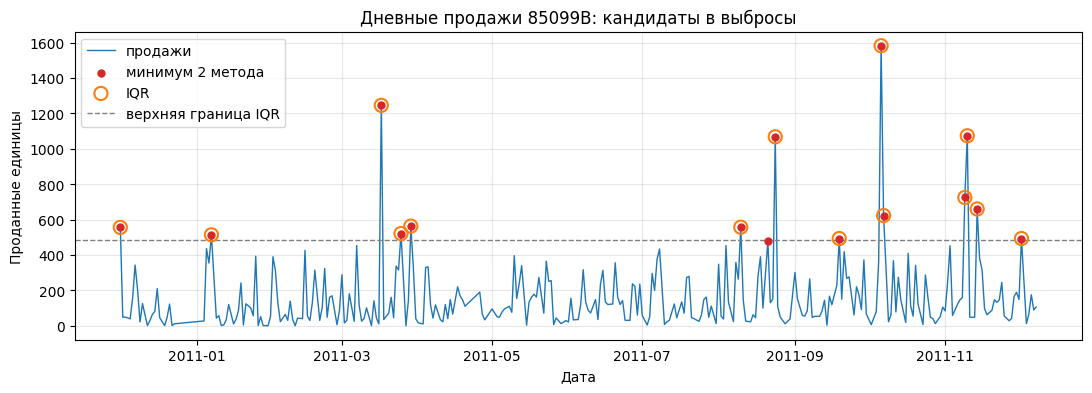

In [42]:
ax = T.plot_series(daily, f"Дневные продажи {STOCK}: кандидаты в выбросы", "Проданные единицы",
                   marks=[(daily[flags["голосов"] >= 2], "минимум 2 метода", "tab:red"),
                          (daily[m_iqr], "IQR", "tab:orange", "ring")])
ax.axhline(hi, ls="--", c="gray", lw=1, label="верхняя граница IQR")
ax.legend()
show("03_outliers")

Методы отметили разное число точек: IQR 14 (граница 486 штук), MAD 15, остаток STL 60. Шестьдесят это почти каждая пятая точка, так что считать все эти отметки выбросами нельзя: остаток после STL остаётся с тяжёлым хвостом, а порог в три робастные сигмы получается слишком узким. Поэтому смотрю на согласие методов: минимум два метода отметили 15 дней, и все 14 точек IQR среди них.

Пятнадцатая, 21 августа 2011 (478 штук), выше границы IQR не поднимается, но её отметили MAD и STL. Самые большие дни: 6 октября (1583 штуки), 17 марта (1246) и 10 ноября (1074). Первый день данных, 1 декабря 2010 (556 штук), тоже попал в список.

Прежде чем что-то менять, посмотрю, из чего состоят самые большие дни. Если это один огромный счёт, то это оптовый заказ, а не ошибка ввода.

In [43]:
for d in cand.index[:3]:
    print("Дата:", d.date(), "| продано за день:", int(daily[d]))
    print(T.inspect_day(prod, d).to_string(index=False))
    print()

Дата: 2011-10-06 | продано за день: 1583
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   569815      1000      1.790  15,838.000 United Kingdom
   569857       200      1.950  12,939.000 United Kingdom
   569740       140      1.790  15,769.000 United Kingdom
   569839       100      1.790  15,769.000 United Kingdom
   569844        20      2.080  12,626.000        Germany

Дата: 2011-03-17 | продано за день: 1246
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   546789      1200      1.650  15,769.000 United Kingdom
   546899        30      1.650  14,298.000 United Kingdom
   546786        10      1.950  16,523.000 United Kingdom
   546896         3      4.130         NaN United Kingdom
   546884         1      4.130         NaN United Kingdom

Дата: 2011-11-10 | продано за день: 1074
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   575582      1000      1.790  16,986.000 United Kingdom
   575683        30      2.080  17,389.000 United Kingdom
   57

Во всех трёх днях картина одинаковая: почти весь день делает один счёт на круглое число штук. 6 октября это 1000 штук из 1583, 17 марта 1200 из 1246, 10 ноября 1000 из 1074. Цена за штуку обычная (1,79; 1,65 и 1,79), количество положительное, а возвраты я убрала ещё при отборе товара. На ошибку ввода это не похоже, скорее на обычные оптовые заказы.

Решение по выбросам: не удаляю. Это фактические продажи, пусть и крупные, а удаление занизило бы спрос и исказило ряд. Надо только помнить, что такие пики дают единичные заказы, а не общий всплеск спроса, и по истории их не предсказать.

Чтобы проверить, что выводы не держатся на нескольких днях, делаю вторую версию ряда: значения ограничены сверху по «дальней» границе Тьюки (k = 3). На обеих версиях проверяю стационарность в шаге 5, остальное считаю по исходному ряду.

Верхняя граница (k=3): 751. Изменено точек: 4 из 304


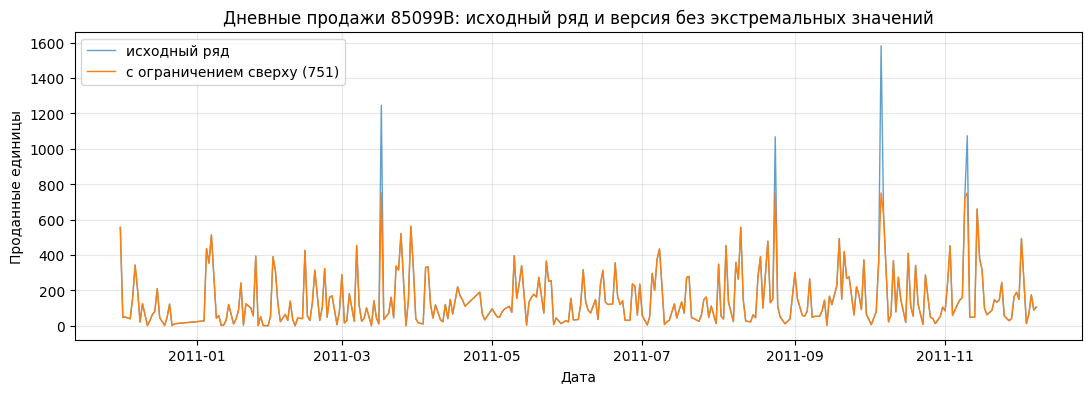

In [44]:
_, (lo3, hi3) = T.iqr_outliers(daily, k=3)
daily_w = T.winsorize(daily, lo=0, hi=hi3)

n_changed = int((daily_w != daily).sum())
print(f"Верхняя граница (k=3): {hi3:.0f}. Изменено точек: {n_changed} из {len(daily)}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, lw=1, label="исходный ряд", alpha=0.7)
ax.plot(daily_w.index, daily_w.values, lw=1, label=f"с ограничением сверху ({hi3:.0f})")
ax.set_title(f"Дневные продажи {STOCK}: исходный ряд и версия без экстремальных значений")
ax.set_xlabel("Дата"); ax.set_ylabel("Проданные единицы"); ax.grid(alpha=0.3); ax.legend()
show("04_winsorized")

Ограничение сверху (751 штука) изменило только 4 дня из 304, а остальной ряд остался прежним. Это четыре самых больших значения ряда. Эта версия нужна как проверка устойчивости, а не как замена исходного ряда.

## Шаг 3. Визуальный и описательный анализ

In [45]:
series = {"день": daily, "неделя": weekly, "месяц": monthly}
desc = pd.DataFrame({k: T.describe_series(v) for k, v in series.items()})
desc

,день,неделя,месяц
count,304.000,52.000,12.000
mean,159.418,925.240,"3,947.750"
std,189.207,483.680,"1,310.255"
min,0.000,181.000,"2,152.000"
25%,43.000,598.500,"2,996.750"
50%,105.500,867.500,"3,651.500"
75%,220.000,"1,073.000","5,314.500"
max,"1,583.000","2,709.000","5,909.000"
skew,3.237,1.285,0.233
kurtosis,16.317,2.893,-1.526


Строки таблицы, которые не стандартные: `cv` это std/mean (разброс относительно уровня), `skew` показывает скошенность вправо, `kurtosis` тяжесть хвостов, `share_zero` долю нулевых периодов, `adi` среднее число периодов между продажами (1 значит, что продажи в каждом периоде), `cv2_nonzero` квадрат коэффициента вариации по ненулевым значениям. По паре adi и cv² принято классифицировать спрос: гладкий, нерегулярный, прерывистый, комковатый.

In [46]:
d = desc["день"]
demand = T.classify_demand(d["adi"], d["cv2_nonzero"])
print(f"ADI = {d['adi']:.2f}, CV² = {d['cv2_nonzero']:.2f} (пороги: ADI 1.32, CV² 0.49) -> "
      f"тип спроса по Syntetos-Boylan: {demand}")
print(f"Скошенность дневных продаж: {d['skew']:.2f}, коэффициент вариации: {d['cv']:.2f}")

ADI = 1.01, CV² = 1.38 (пороги: ADI 1.32, CV² 0.49) -> тип спроса по Syntetos-Boylan: нерегулярный, продажи почти каждый день, но объёмы скачут
Скошенность дневных продаж: 3.24, коэффициент вариации: 1.19


Дневной ряд. Среднее 159,4 заметно выше медианы 105,5, распределение скошено вправо (скошенность 3,24, эксцесс 16,3) из-за редких крупных заказов. Стандартное отклонение (189,2) больше среднего, коэффициент вариации 1,19, так что продажи день ото дня очень неровные. Половина дней лежит между 43 и 220 штуками, максимум 1583.

Чем крупнее период, тем спокойнее ряд: коэффициент вариации 1,19 по дням, 0,523 по неделям и 0,332 по месяцам, скошенность 3,24, 1,285 и 0,233. Крупные заказы растворяются в сумме. Правда, в месячном ряду только 12 точек.

Тип спроса. ADI = 1,01, то есть товар продаётся почти в каждый торговый день, нулей всего 1,3%, так что спрос не прерывистый. CV² = 1,38 больше порога 0,49, поэтому по классификации Syntetos-Boylan спрос нерегулярный: продажи есть всегда, но размер заказа сильно меняется. Скорее всего, недельные суммы предсказать проще, чем отдельные дни.

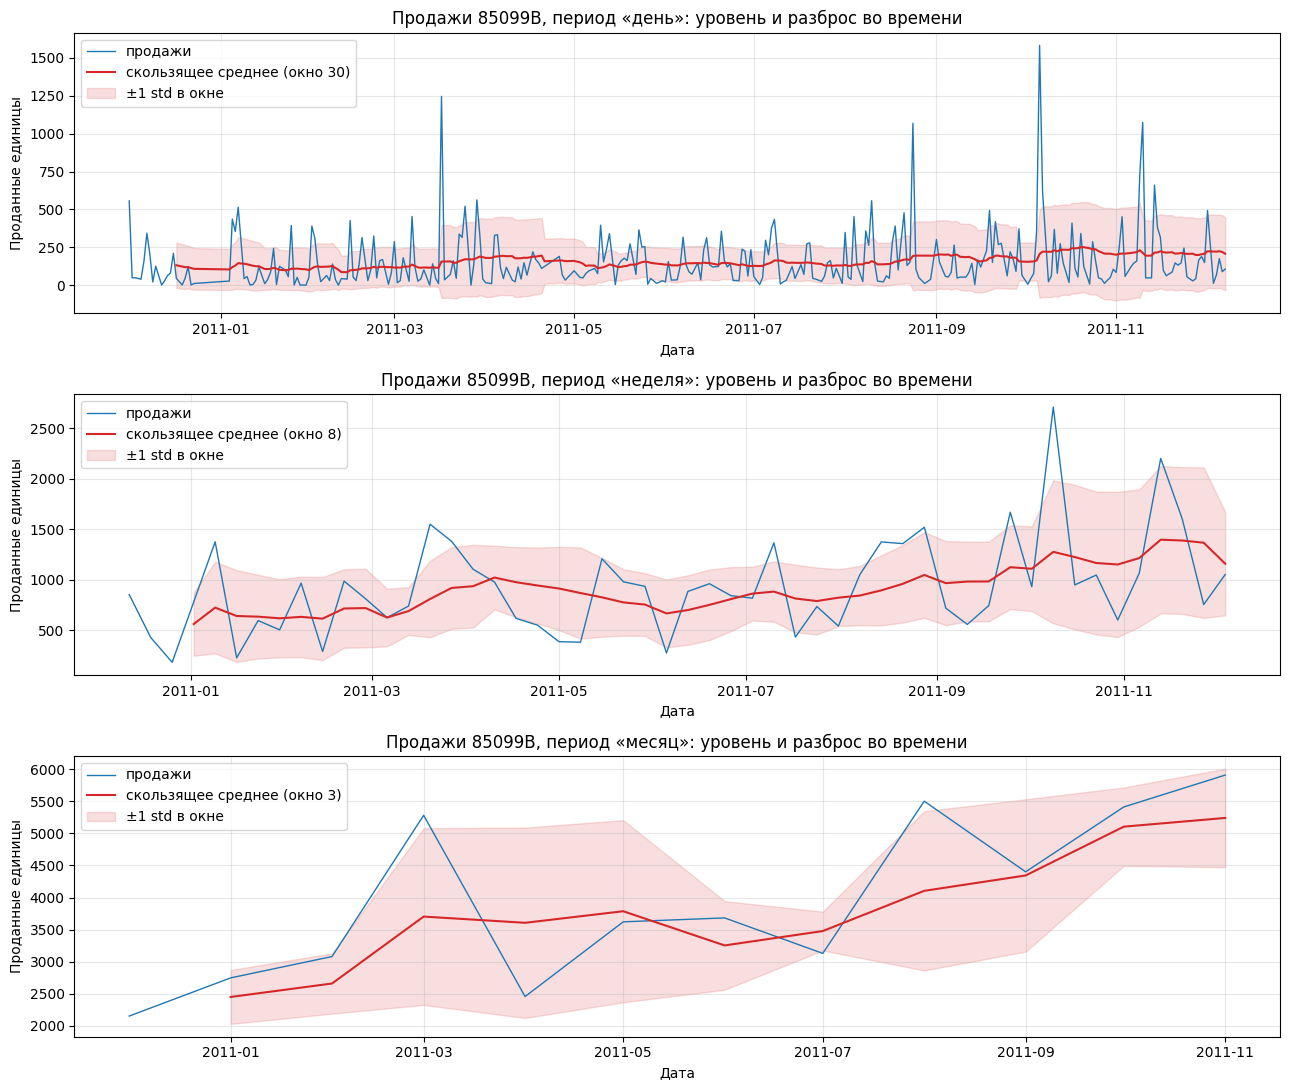

In [47]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, (name, s, w) in zip(axes, [("день", daily, 30), ("неделя", weekly, 8), ("месяц", monthly, 3)]):
    rs = T.rolling_stats(s, w)
    T.plot_series(s, f"Продажи {STOCK}, период «{name}»: уровень и разброс во времени",
                  "Проданные единицы", ax=ax)
    ax.plot(rs.index, rs["mean"], c="tab:red", label=f"скользящее среднее (окно {w})")
    ax.fill_between(rs.index, rs["mean"] - rs["std"], rs["mean"] + rs["std"],
                    color="tab:red", alpha=0.15, label="±1 std в окне")
    ax.legend()
fig.tight_layout()
show("05_level_and_spread")

In [48]:
print("Линейный тренд (наклон в единицах за период):")
for name, s in series.items():
    tr = T.trend_slope(s)
    print(f"  {name:7s} наклон {tr['slope']:+.3f}, p-value {tr['pvalue']:.3f}, R² {tr['r2']:.3f}")

rs = T.rolling_stats(weekly, 8).dropna()
corr_ms = rs["mean"].corr(rs["std"])
print(f"\nКорреляция скользящего среднего и скользящего std (недели): {corr_ms:.2f}")
print("Чем выше она, тем сильнее разброс растёт вместе с уровнем, и тем оправданнее логарифм.")

Линейный тренд (наклон в единицах за период):
  день    наклон +0.309, p-value 0.012, R² 0.021
  неделя  наклон +13.023, p-value 0.003, R² 0.166
  месяц   наклон +271.815, p-value 0.005, R² 0.559

Корреляция скользящего среднего и скользящего std (недели): 0.77
Чем выше она, тем сильнее разброс растёт вместе с уровнем, и тем оправданнее логарифм.


Уровень растёт: на графике скользящее среднее в дневном, недельном и месячном ряду идёт вверх к осени. Линейный тренд это подтверждает: +0,309 штуки за торговый день (p = 0,012), +13,02 за неделю (p = 0,003) и +271,8 за месяц (p = 0,005). R² растёт с укрупнением периода: 0,021, 0,166 и 0,559. В дневных данных шум заглушает тренд, а в месячных тренд объясняет больше половины дисперсии. Но в месячном ряду всего 12 точек, а p-value обычной регрессии для временных рядов оптимистичны, потому что остатки коррелированы.

Оговорка: данных чуть больше года, и рост приходится на осень, то есть на предрождественский сезон. Отделить настоящий долгосрочный тренд от годовой сезонности на таком ряду нельзя.

Разброс тоже растёт вместе с уровнем: полоса ±1 std на графике осенью шире, чем зимой, а корреляция скользящего среднего и скользящего std по неделям равна 0,77. Значит, дисперсия непостоянна, и стабилизировать её, например логарифмом, имеет смысл.

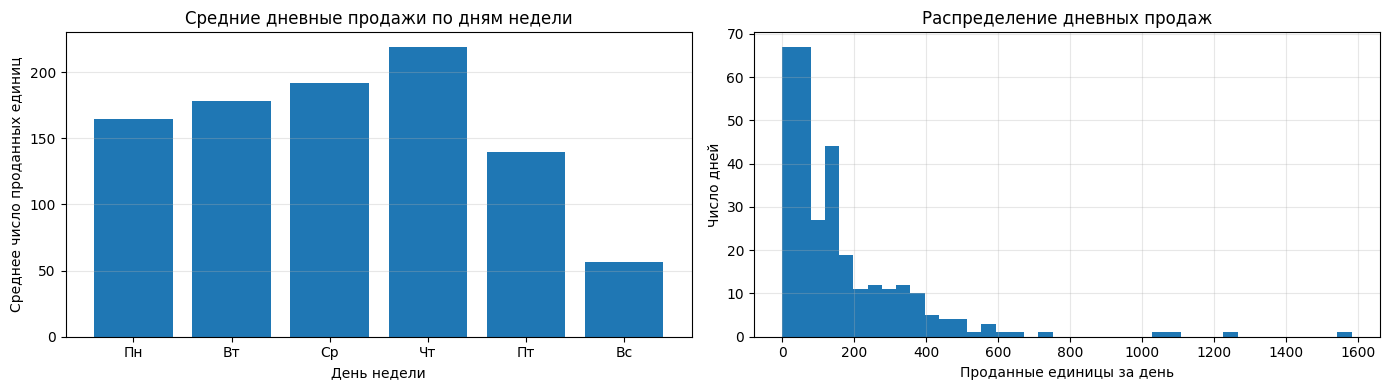

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

wd = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_wd = daily.groupby(daily.index.dayofweek).mean()
axes[0].bar([wd[i] for i in by_wd.index], by_wd.values)
axes[0].set_title("Средние дневные продажи по дням недели")
axes[0].set_xlabel("День недели"); axes[0].set_ylabel("Среднее число проданных единиц")
axes[0].grid(axis="y", alpha=0.3)

axes[1].hist(daily.values, bins=40)
axes[1].set_title("Распределение дневных продаж")
axes[1].set_xlabel("Проданные единицы за день"); axes[1].set_ylabel("Число дней")
axes[1].grid(alpha=0.3)
fig.tight_layout()
show("06_weekday_and_hist")

По дням недели самым слабым выглядит воскресенье, самым сильным четверг, а пятница ниже остальных будних дней. Гистограмма показывает тот же перекос, что и статистики: много дней с небольшими продажами и длинный хвост до 1583 штук.

## Шаг 4. Декомпозиция и сезонность

Беру STL с `robust=True`: он устойчив к выбросам (а я их не удаляла), позволяет сезонному профилю медленно меняться и работает с любым периодом. Для сравнения считаю ещё классическую декомпозицию (`seasonal_decompose`). Модель аддитивная, потому что в ряду есть нули, а мультипликативная с ними не работает. Если окажется, что разброс растёт вместе с уровнем, в шаге 5 проверю, помогает ли логарифм.

Период. Ряд идёт по торговым дням, поэтому неделя это не 7 дней, а столько, сколько дней недели реально торгуют (`PERIOD_D`, он равен 6).

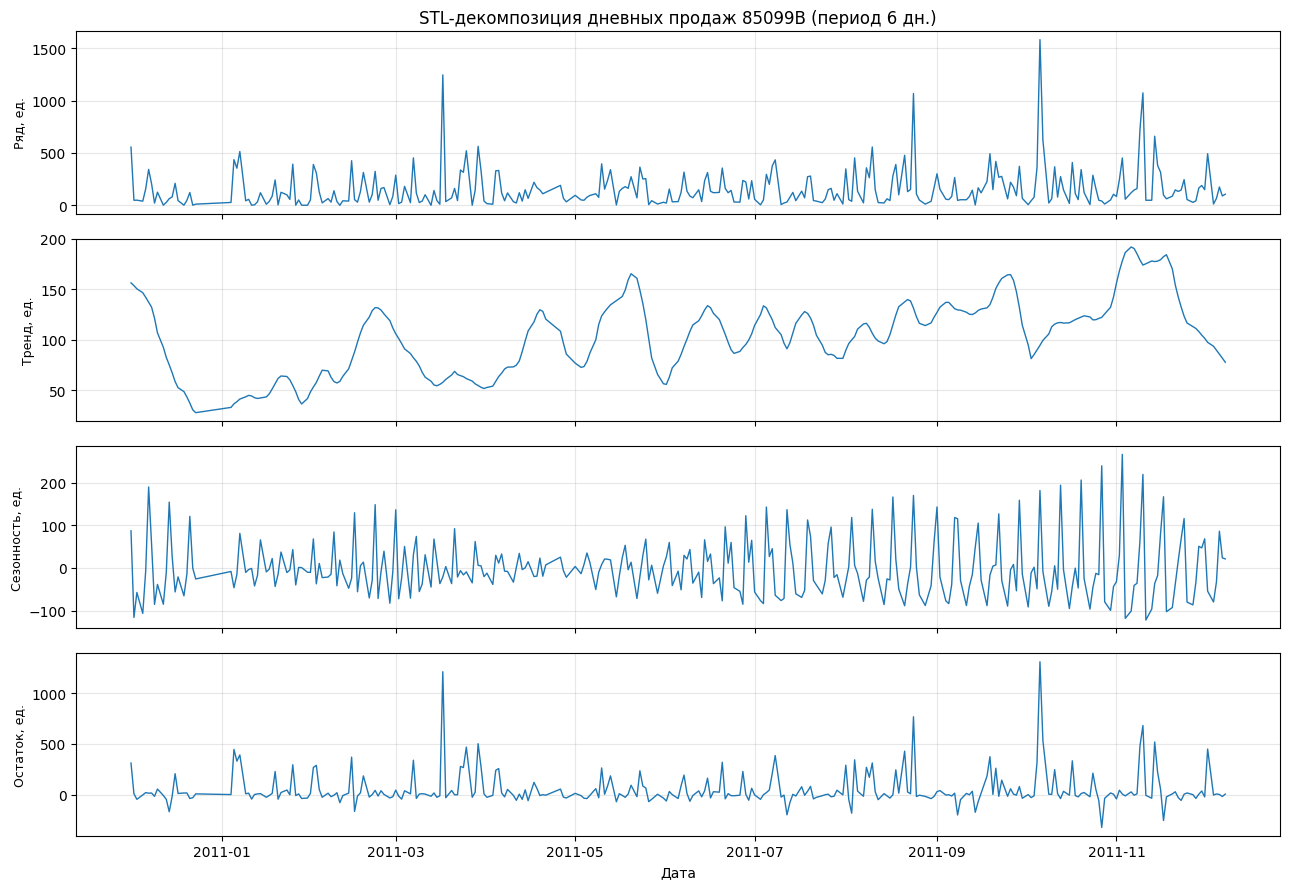

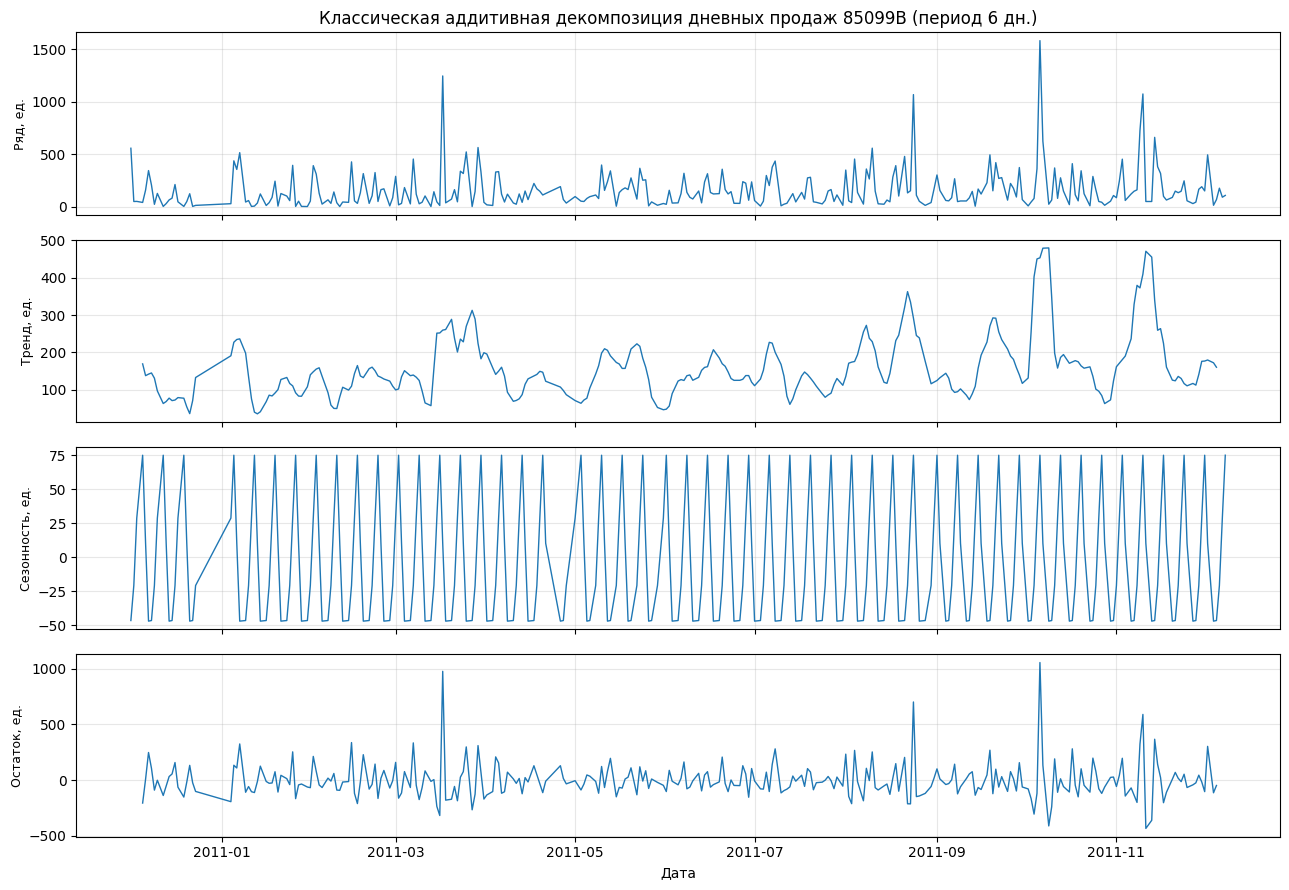

Сила компонент (0 - нет, 1 - доминирует), по Хайндману:
  STL:         сезонность 0.168, тренд 0.038
  классическая: сезонность 0.068, тренд 0.230


In [50]:
res_stl = T.decompose(daily, PERIOD_D, "stl")
res_cl = T.decompose(daily, PERIOD_D, "classic", model="additive")

T.plot_decomposition(res_stl, f"STL-декомпозиция дневных продаж {STOCK} (период {PERIOD_D} дн.)", "ед.")
show("07_stl")
T.plot_decomposition(res_cl, f"Классическая аддитивная декомпозиция дневных продаж {STOCK} (период {PERIOD_D} дн.)", "ед.")
show("08_classic")

st_stl = T.seasonal_strength(res_stl)
st_cl = T.seasonal_strength(res_cl)
print("Сила компонент (0 - нет, 1 - доминирует), по Хайндману:")
print(f"  STL:         сезонность {st_stl['seasonal_strength']:.3f}, тренд {st_stl['trend_strength']:.3f}")
print(f"  классическая: сезонность {st_cl['seasonal_strength']:.3f}, тренд {st_cl['trend_strength']:.3f}")

Тренд. В STL он плавный, но не монотонный: общий наклон вверх, с несколькими локальными горбами осенью, это согласуется с шагом 3. Крупные заказы тренд не уводят, потому что STL робастный.

Сезонная составляющая. Виден повторяющийся шестидневный профиль, но его размах меняется во времени: осенью он заметно больше, чем зимой и весной. То есть недельный эффект растёт вместе с уровнем продаж и больше похож на процент от продаж, чем на фиксированную добавку. В классической декомпозиции профиль один и тот же на весь ряд.

Остаток. Почти весь около нуля, с редкими всплесками в те же дни, что и крупные заказы (17 марта, 6 октября и другие из списка выше). Робастный STL оставляет их в остатке, а не прячет в тренд. В классической декомпозиции тренд считается обычным скользящим средним, поэтому он на эти всплески реагирует и выглядит «иголчатым».

Сила компонент по Хайндману (0 значит, что компоненты нет, 1 что она доминирует): у STL сезонность 0,168 и тренд 0,038, у классической 0,068 и 0,230. Сезонность в обоих случаях слабая. Разница в силе тренда (0,038 против 0,230) как раз из-за того, что классический тренд подхватывает выбросы, так что для этого ряда я больше доверяю STL.

Сезонность проверю четырьмя способами: сила сезонной компоненты STL, автокорреляция на лаге, равном периоду, критерий Краскела-Уоллиса по дням недели (H0: во все дни недели продажи распределены одинаково) и пики амплитудного спектра. Порог 0,3 для силы сезонности я выбрала ориентировочно, общепринятого жёсткого значения нет.

In [51]:
acf_vals, bound = T.acf_at_lags(daily, [1, PERIOD_D, 2 * PERIOD_D])
print(f"ACF на лагах (доверительная граница ±{bound:.3f}):")
print(acf_vals.round(3).to_string())

kw_stat, kw_p = T.weekday_kruskal(daily)
print(f"\nКраскел-Уоллис по дням недели: H = {kw_stat:.2f}, p-value = {kw_p:.4f}")

peaks = T.spectrum_peaks(daily, top=5)
print("\nТоп пиков амплитудного спектра (период в днях ряда):")
print(peaks.round(2).to_string(index=False))

signs = {
    f"сила сезонности STL > 0.3 ({st_stl['seasonal_strength']:.2f})": st_stl["seasonal_strength"] > 0.3,
    f"ACF на лаге {PERIOD_D} выше границы ({acf_vals[PERIOD_D]:.2f})": acf_vals[PERIOD_D] > bound,
    f"Краскел-Уоллис p < 0.05 ({kw_p:.3f})": kw_p < 0.05,
    f"пик спектра рядом с периодом {PERIOD_D}": bool((np.abs(peaks["period"] - PERIOD_D) < 0.5).any()),
}
print("\nПризнаки недельной сезонности:")
for k, v in signs.items():
    print(f"  [{'да' if v else 'нет'}] {k}")
n_yes = sum(signs.values())
season_verdict = T.season_verdict(n_yes, st_stl["seasonal_strength"])
print(f"\nИтог: недельная сезонность {season_verdict} ({n_yes} из 4 признаков).")

ACF на лагах (доверительная граница ±0.112):
1    0.158
6    0.120
12   0.038

Краскел-Уоллис по дням недели: H = 46.96, p-value = 0.0000

Топ пиков амплитудного спектра (период в днях ряда):
 period  amplitude
  5.960     59.580
  2.980     48.000
 12.670     45.050
 38.000     44.820
  5.430     44.450

Признаки недельной сезонности:
  [нет] сила сезонности STL > 0.3 (0.17)
  [да] ACF на лаге 6 выше границы (0.12)
  [да] Краскел-Уоллис p < 0.05 (0.000)
  [да] пик спектра рядом с периодом 6

Итог: недельная сезонность статистически значима, но слабая (3 из 4 признаков).


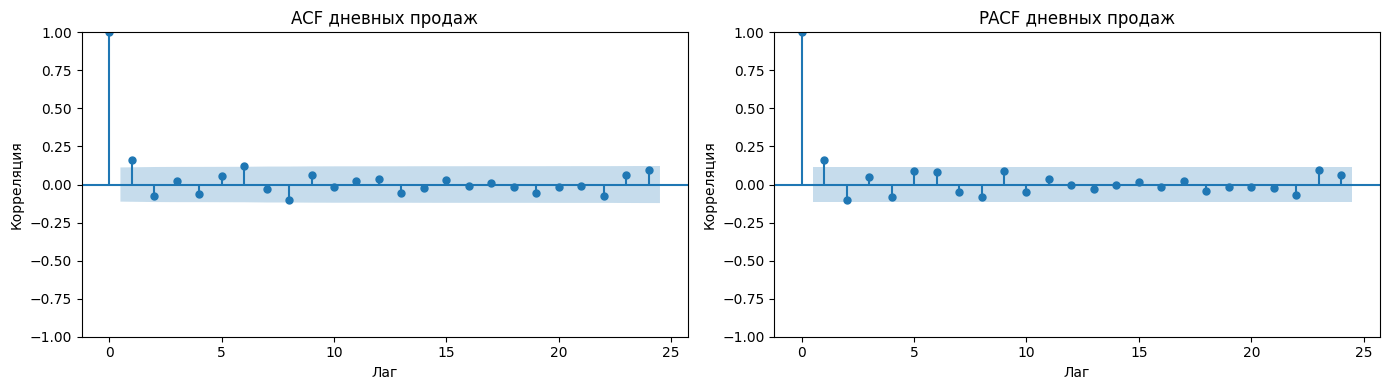

In [52]:
T.plot_acf_pacf(daily, lags=3 * PERIOD_D + 6, suffix="дневных продаж")
show("09_acf_pacf")

Три проверки из четырёх говорят «да», но по-разному. Критерий Краскела-Уоллиса убедителен (H = 46,96, p близко к нулю): продажи по дням недели действительно различаются. В спектре самый высокий пик стоит на периоде 5,96, то есть на шести днях, но следующие пики (12,67; 38 и 5,43 дня) лишь немного ниже, так что резко он не выделяется. ACF на лаге 6 равна 0,120 при границе 0,112, то есть едва выше неё, а на лаге 12 повторения нет (0,038). Сила сезонности STL всего 0,168, ниже моего порога.

Вывод: недельная сезонность с периодом 6 торговых дней есть и статистически значима, но слабая. Она объясняет малую часть изменчивости, а большая часть колебаний это случайные заказы.

По ACF и PACF: корреляция соседних дней 0,158, дальше почти всё внутри доверительной полосы. Автокорреляции в ряду мало, он ближе к шуму с небольшой памятью о предыдущем дне и слабым недельным циклом.

### Годовая сезонность

Для годового цикла нужно минимум два полных периода, иначе его не отделить от тренда. Проверю, сколько данных у меня есть.

In [53]:
for name, s, per in [("неделя", weekly, 52), ("месяц", monthly, 12)]:
    ok = len(s) >= 2 * per
    print(f"{name}: наблюдений {len(s)}, нужно минимум {2 * per} для периода {per} -> "
          f"{'можно оценивать' if ok else 'оценить нельзя'}")

неделя: наблюдений 52, нужно минимум 104 для периода 52 -> оценить нельзя
месяц: наблюдений 12, нужно минимум 24 для периода 12 -> оценить нельзя


Данных чуть больше года (52 недели и 12 месяцев), поэтому годовую сезонность по ним оценить нельзя: рост продаж к осени неотличим от тренда или разового события. Это ограничение датасета, а не доказательство того, что сезонности нет.

## Шаг 5. Стационарность

Использую два теста с противоположными нулевыми гипотезами:

* ADF: H0 это единичный корень, то есть ряд нестационарен. Если p < 0,05, H0 отвергается и ряд стационарен.
* KPSS: H0 это стационарность. Если p < 0,05, H0 отвергается и ряд нестационарен.

Уверенный вывод получается, когда тесты согласны. Если они расходятся, по одному тесту решать нельзя: возможно, ряд стационарен вокруг тренда или данных мало. В обоих тестах стоит регрессия с константой, число лагов в ADF подбирается по AIC, в KPSS автоматически.

Проверяю дневной ряд, его версию без экстремумов и недельный ряд. Месячный слишком короткий для этих тестов.

In [54]:
checks = {"дни (исходный)": daily, "дни (без экстремумов)": daily_w, "недели": weekly}
orig_tabs = {}
for name, s in checks.items():
    tab, verdict = T.stationarity_tests(s, name="")
    orig_tabs[name] = (tab, verdict)
    print(f"=== {name} ===")
    print(tab.to_string())
    print("Вывод:", verdict, "\n")

=== дни (исходный) ===
        stat  p-value  lags                H0
ADF  -12.417    0.000     1  единичный корень
KPSS   0.597    0.023     1    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 

=== дни (без экстремумов) ===
       stat  p-value  lags                H0
ADF  -5.356    0.000     8  единичный корень
KPSS  0.623    0.021     2    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 

=== недели ===
       stat  p-value  lags                H0
ADF  -5.719    0.000     0  единичный корень
KPSS  0.674    0.016     2    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 



У всех трёх вариантов картина одна и та же. ADF уверенно отвергает единичный корень (статистики -12,417, -5,356 и -5,719, p-value в выводе 0,000), а KPSS отвергает стационарность на уровне 5% (p = 0,023, 0,021 и 0,016), но не на уровне 1%. Тесты расходятся.

Читаю это так. ADF говорит, что случайного блуждания в ряду нет. KPSS замечает, что среднее непостоянно: оно растёт к осени, это видно в шаге 3. Значит, стохастического тренда нет, но есть медленно меняющийся уровень, и строго стационарным (с постоянным средним) ряд считать нельзя. На ряду без экстремумов результат тот же, так что крупные заказы тут ни при чём.

Если ряд нестационарен или тесты расходятся, подбираю преобразование от простого к сложному: логарифм (`log1p`, потому что есть нули), обычная разность, их комбинация, потом сезонная разность. Беру первое, после которого оба теста согласны.

In [55]:
cands_d = [dict(log=False, d=0), dict(log=True, d=0), dict(log=False, d=1), dict(log=True, d=1),
           dict(log=False, d=0, seasonal_lag=PERIOD_D), dict(log=True, d=1, seasonal_lag=PERIOD_D)]
cands_w = [dict(log=False, d=0), dict(log=True, d=0), dict(log=False, d=1), dict(log=True, d=1)]

chosen_d, tab_d = T.choose_transformation(daily, cands_d)
chosen_w, tab_w = T.choose_transformation(weekly, cands_w)

print("Дневной ряд, все попытки:")
print(tab_d.to_string(index=False))
print("\nВыбрано:", chosen_d)
print("\nНедельный ряд, все попытки:")
print(tab_w.to_string(index=False))
print("\nВыбрано:", chosen_w)

Дневной ряд, все попытки:
  log  d  ADF p  KPSS p                                              вердикт  seasonal_lag
False  0  0.000   0.023 тесты расходятся: ADF за стационарность, KPSS против           NaN
 True  0  0.014   0.010 тесты расходятся: ADF за стационарность, KPSS против           NaN
False  1  0.000   0.100                     стационарен (оба теста согласны)           NaN
 True  1  0.000   0.100                     стационарен (оба теста согласны)           NaN
False  0  0.000   0.100                     стационарен (оба теста согласны)         6.000
 True  1  0.000   0.100                     стационарен (оба теста согласны)         6.000

Выбрано: {'log': False, 'd': 1}

Недельный ряд, все попытки:
  log  d  ADF p  KPSS p                                              вердикт
False  0  0.000   0.016 тесты расходятся: ADF за стационарность, KPSS против
 True  0  0.000   0.010 тесты расходятся: ADF за стационарность, KPSS против
False  1  0.021   0.100                     

In [56]:
def apply_and_check(s, chosen, name):
    if chosen is None:
        chosen = dict(log=True, d=1)
        print(f"{name}: ни один вариант не прошёл оба теста, беру log1p + разность как наиболее мягкий")
    z = T.make_stationary(s, **chosen)
    tab, verdict = T.stationarity_tests(z)
    print(f"=== {name}: после преобразования {chosen} ===")
    print(tab.to_string())
    print("Вывод:", verdict, "\n")
    return z, chosen, tab, verdict

daily_st, used_d, tab_d2, v_d2 = apply_and_check(daily, chosen_d, "дни")
weekly_st, used_w, tab_w2, v_w2 = apply_and_check(weekly, chosen_w, "недели")

=== дни: после преобразования {'log': False, 'd': 1} ===
       stat  p-value  lags                H0
ADF  -9.272    0.000     9  единичный корень
KPSS  0.096    0.100    30    стационарность
Вывод: стационарен (оба теста согласны) 

=== недели: после преобразования {'log': False, 'd': 1} ===
       stat  p-value  lags                H0
ADF  -3.176    0.021    11  единичный корень
KPSS  0.086    0.100     6    стационарность
Вывод: стационарен (оба теста согласны) 



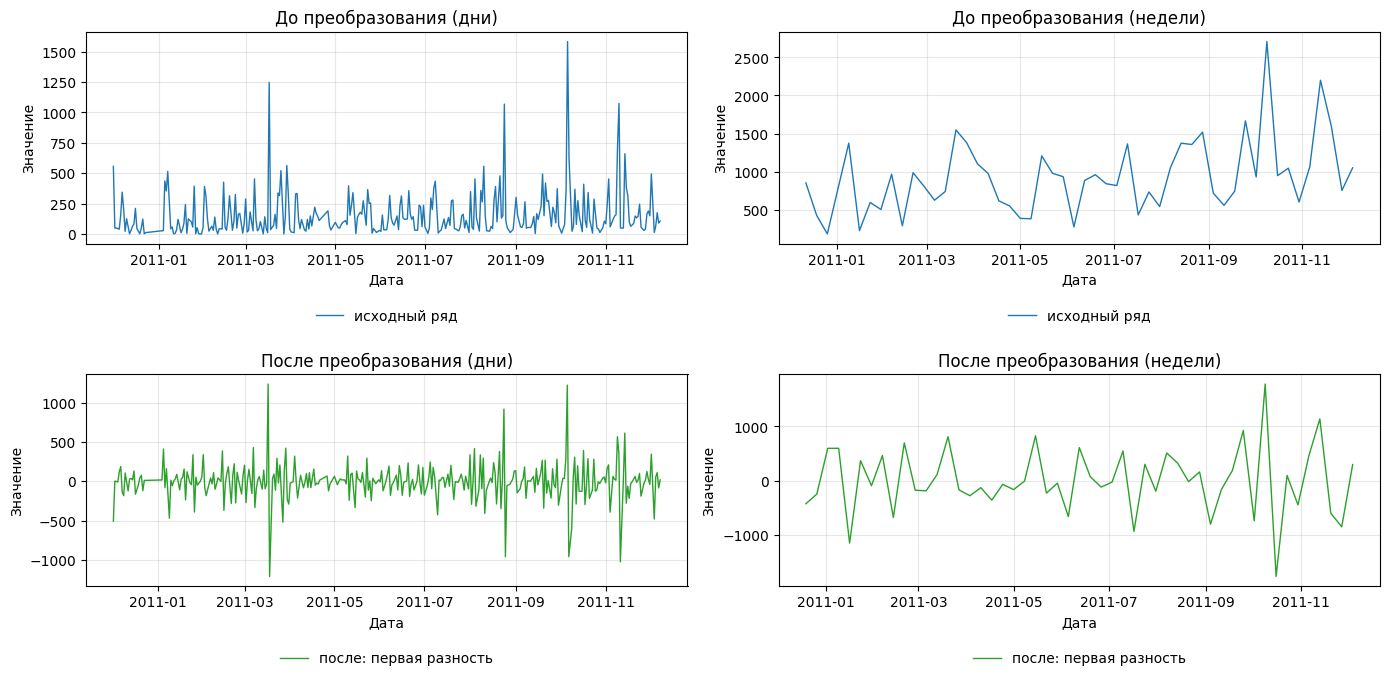

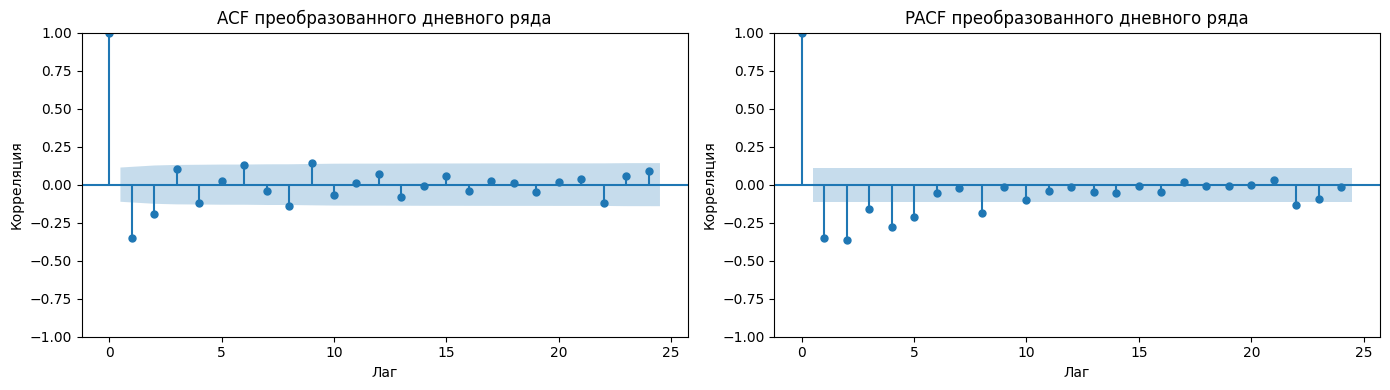

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for col, (s, z, name, used) in enumerate([(daily, daily_st, "дни", used_d), (weekly, weekly_st, "недели", used_w)]):
    axes[0, col].plot(s.index, s.values, lw=1, label="исходный ряд")
    axes[0, col].set_title(f"До преобразования ({name})")
    axes[1, col].plot(z.index, z.values, lw=1, c="tab:green", label=f"после: {T.transform_name(used)}")
    axes[1, col].set_title(f"После преобразования ({name})")
    for ax in axes[:, col]:
        ax.set_xlabel("Дата"); ax.set_ylabel("Значение"); ax.grid(alpha=0.3)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
fig.tight_layout()
show("10_before_after")

T.plot_acf_pacf(daily_st, lags=3 * PERIOD_D + 6, suffix="преобразованного дневного ряда")
show("11_acf_after")

Логарифм сам по себе вопрос не решает: расхождение тестов остаётся, а у дневного ряда после логарифма KPSS даже хуже (p = 0,010 против 0,023). Первая разность решает его и для дневного, и для недельного ряда, оба теста согласны. Я взяла первую разность без логарифма как самое простое преобразование, после которого оба теста согласны. Логарифм с разностью тоже проходит оба теста, а у дневного ряда ещё и сезонная разность с лагом 6, так что это запасные варианты. Логарифм пригодится, если на моделировании понадобится убрать рост разброса: после разности он на графике остаётся, осенью колебания шире.

Есть и минус. На ACF и PACF разностного ряда лаг 1 уходит заметно ниже доверительной полосы, а у исходного ряда автокорреляция на этом лаге была положительной (0,158). Это признак того, что ряд немного «переразностили»: разность добавляет искусственную отрицательную автокорреляцию и шум. Формально преобразование выполнено и подтверждено тестами, но о реальной динамике по разностному ряду судить нельзя.

## Шаг 6. Выводы

Данные и ряд. Я анализировала товар 85099B (JUMBO BAG RED RETROSPOT), показатель продаж это количество проданных штук без возвратов, период с 1 декабря 2010 по 9 декабря 2011. Получилось 373 дня (304 после перехода на торговый календарь), 52 недели и 12 месяцев, неполные периоды по краям отброшены.

Качество данных. Пустых дней 73 из 373, но в 69 из них магазин не работал (53 из этих дней субботы), поэтому нулями я их не заменяла, а убрала из дневного ряда. Настоящих нулей 4. В недельном ряду одна пустая неделя в рождественский перерыв, я её интерполировала.

Выбросы. IQR отметил 14 точек, MAD 15, остаток STL 60 (слишком много, метод чувствителен к тяжёлому хвосту), минимум два метода согласились на 15 днях. В трёх самых больших днях почти весь объём даёт один круглый заказ (1000 из 1583, 1200 из 1246, 1000 из 1074). Выбросы я не удаляла, потому что это фактические продажи. Для проверки сделала версию с ограничением сверху (751 штука, изменено 4 дня из 304), на стационарности вывод тот же.

Описание ряда. Среднее дневных продаж 159,4 при медиане 105,5, скошенность 3,24, коэффициент вариации 1,19 (по неделям 0,523, по месяцам 0,332). Спрос нерегулярный (ADI = 1,01, CV² = 1,38). Уровень растёт к осени (по неделям +13,02 штуки за неделю, p = 0,003), разброс растёт вместе с уровнем (корреляция скользящего среднего и std по неделям 0,77).

Сезонность. Недельная сезонность с периодом 6 торговых дней статистически значима (критерий Краскела-Уоллиса H = 46,96, p близко к нулю), но слабая: сила сезонности STL 0,168, ACF на лаге 6 едва выше границы (0,120 при 0,112). Годовую сезонность оценить нельзя: данных чуть больше года, и рост к осени неотличим от тренда.

Стационарность. У исходных рядов ADF отвергает единичный корень (p-value 0,000), а KPSS отвергает стационарность (p от 0,016 до 0,023). Тесты расходятся: случайного блуждания нет, но есть медленно растущий уровень. Первая разность делает оба теста согласными (дневной ряд: ADF p-value 0,000, KPSS p-value 0,100; недельный: ADF p = 0,021, KPSS p-value 0,100). Цена преобразования: на ACF разностного ряда лаг 1 уходит заметно ниже полосы, то есть ряд немного переразностен.

Ограничения. Один год данных. В месячном ряду 12 точек. Не проверяла, были ли крупные заказы потом отменены отдельными счетами-возвратами.